In [ ]:
# !pip install cudaq==0.11.0

In [2]:
import numpy as np
import pandas as pd
from functools import lru_cache
from types import SimpleNamespace
from pathlib import Path
try:
    import cudaq
    from cudaq import spin
    HAS_CUDAQ = True
except ImportError:
    HAS_CUDAQ = False
import sys
import os
import torch
from typing import List, Tuple
from torch.optim import Adam, AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR, CosineAnnealingWarmRestarts, ReduceLROnPlateau, ExponentialLR, CyclicLR, SequentialLR
from tqdm import tqdm
from math import sqrt
import matplotlib.pyplot as plt

In [3]:
# Exact CPU fallback for the diagonal Ising Hamiltonians in this notebook.
# This implements the same QAOA unitary, not a classical portfolio heuristic.
if not HAS_CUDAQ:
    class ZOperator:
        def __init__(self, terms):
            self.terms = {frozenset(k): float(v) for k, v in terms.items()}

        def __add__(self, other):
            if np.isscalar(other):
                other = ZOperator({frozenset(): other})
            terms = self.terms.copy()
            for key, value in other.terms.items():
                terms[key] = terms.get(key, 0.0) + value
            return ZOperator(terms)

        __radd__ = __add__

        def __neg__(self):
            return self * -1

        def __sub__(self, other):
            return self + (-other)

        def __rsub__(self, other):
            return -self + other

        def __mul__(self, other):
            if np.isscalar(other):
                return ZOperator({key: value * other for key, value in self.terms.items()})
            terms = {}
            for a, ca in self.terms.items():
                for b, cb in other.terms.items():
                    key = a ^ b  # Z_i squared is identity.
                    terms[key] = terms.get(key, 0.0) + ca * cb
            return ZOperator(terms)

        __rmul__ = __mul__

        def canonicalize(self):
            return self

        def get_raw_data(self):
            n = max((max(key, default=-1) for key in self.terms), default=-1) + 1
            keys = list(self.terms)
            return ([[False] * n + [i in key for i in range(n)] for key in keys],
                    [complex(self.terms[key]) for key in keys])

        def diagonal(self, n):
            z = _z_values(n)
            energy = np.zeros(1 << n)
            for key, value in self.terms.items():
                term = np.ones(1 << n)
                for i in key:
                    term *= z[i]
                energy += value * term
            return energy

    @lru_cache(maxsize=None)
    def _z_values(n):
        indices = np.arange(1 << n)
        return 1 - 2 * ((indices[None, :] >> np.arange(n)[:, None]) & 1)

    @lru_cache(maxsize=32)
    def _cost_diagonal(n, idx_1, coeff_1, idx_a, idx_b, coeff_2):
        z = _z_values(n)
        energy = np.zeros(1 << n)
        for i, c in zip(idx_1, coeff_1):
            energy += c * z[i]
        for a, b, c in zip(idx_a, idx_b, coeff_2):
            energy += c * z[a] * z[b]
        return energy

    def _get_state(kernel, *args):
        if kernel.__name__ == 'kernel_flipped':
            state, n = args
            # Convert CUDA-Q's little-endian state indices to displayed bitstrings.
            return np.asarray(state).reshape([2] * n).transpose(tuple(reversed(range(n)))).reshape(-1).copy()
        theta, n, L, i1, c1, ia, ib, c2 = args
        diagonal = _cost_diagonal(n, tuple(i1), tuple(c1), tuple(ia), tuple(ib), tuple(c2))
        state = np.full(1 << n, 1 / np.sqrt(1 << n), dtype=complex)
        for layer in range(L):
            # All cost terms commute, so their combined diagonal phase is exact.
            state *= np.exp(-1j * theta[layer] * diagonal)
            c, s = np.cos(theta[L + layer]), -1j * np.sin(theta[L + layer])
            for qubit in range(n):
                blocks = state.reshape(-1, 2, 1 << qubit)
                a, b = blocks[:, 0, :].copy(), blocks[:, 1, :].copy()
                blocks[:, 0, :], blocks[:, 1, :] = c * a + s * b, s * a + c * b
        return state

    def _observe(kernel, operator, *args):
        state = _get_state(kernel, *args)
        energy = float(np.dot(np.abs(state)**2, operator.diagonal(args[1])))
        return SimpleNamespace(expectation=lambda: energy)

    spin = SimpleNamespace(i=lambda i: ZOperator({frozenset(): 1}),
                           z=lambda i: ZOperator({frozenset([i]): 1}))
    cudaq = SimpleNamespace(SpinOperator=ZOperator, State=np.ndarray,
                           kernel=lambda fn: fn, get_state=_get_state, observe=_observe,
                           draw=lambda *args: 'NumPy backend: H on each qubit; L layers of RZ, CX-RZ-CX, RX.')
print('Backend:', 'CUDA-Q' if HAS_CUDAQ else 'NumPy exact state-vector (CPU)')

Backend: NumPy exact state-vector (CPU)


# Feel free to modify the following parameters as needed

### Objective of this problem is to
$$
\max_{\mathbf{x}} \left\{ \mu^\top \mathbf{x} - q \mathbf{x}^\top C \mathbf{x}\right\} \\
\text{s.t. } \sum_{i=1}^n x_i = 1
$$
where 
- $\mathbf{x}$ is the decision variable
- $\mu$ is the expected return vector
- $C$ is the covariance matrix of returns
- q is the risk aversion parameter, $P$ is the price vector
- $\lambda$ is a penalty parameter for budget constraint violation.

In [4]:
seed = 55
# Find the data whether launched from this folder or the repository root.
dataset_dir = next((p for p in (Path('dataset'), Path('Lab/QAOA_Portfolio_Optimization/dataset'))
                    if p.is_dir()), None)
if dataset_dir is None:
    raise FileNotFoundError('Run from the notebook directory or repository root.')
budget = 1000
lamb = 0.0005
q = 1.5
n_assets = 4
layer_count = 5
hamiltonian_boost = 5000
is_pbar = True

np.random.seed(seed)
torch.manual_seed(seed)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if HAS_CUDAQ:
    cudaq.set_target('nvidia' if cudaq.num_available_gpus() > 0 else 'qpp-cpu')
    cudaq.set_random_seed(seed)

data_cov_pd = pd.read_csv(os.path.join(dataset_dir, "top_50_us_stocks_data_20250526_011226_covariance.csv"))
data_ret_p_pd = pd.read_csv(os.path.join(dataset_dir, "top_50_us_stocks_returns_price.csv"))

# Align by ticker, rather than assuming CSV row orders always agree.
data_cov_pd = data_cov_pd.set_index('Ticker')
data_ret_p_pd = data_ret_p_pd.set_index('Ticker').loc[data_cov_pd.index].reset_index()
data_cov_pd = data_cov_pd.loc[:, data_cov_pd.index].reset_index()
asset_idx = np.random.choice(data_cov_pd.shape[0], n_assets, replace=False)
data_cov = data_cov_pd.drop("Ticker", axis=1).to_numpy()[asset_idx, :][:, asset_idx]
stock_names = data_ret_p_pd["Company_Name"].to_numpy()[asset_idx]
# print("Selected Stocks: ", stock_names.tolist())
data_ret_p = data_ret_p_pd.drop("Ticker", axis=1)
asset_idx_raw = data_ret_p.index[asset_idx].to_numpy()
data_ret_p = data_ret_p.drop("Company_Name", axis=1).to_numpy()[asset_idx, :]
data_ret = data_ret_p[:, 0]
data_p = data_ret_p[:, 1]

for i in range(n_assets):
    print(f"Stock: {stock_names[i]}, Return: {data_ret[i]:.4f}, Price: {data_p[i]:.2f}")

P = data_p
ret = data_ret
cov = data_cov
B = budget
parameter_count = 2 * layer_count

Stock: Accenture plc, Return: 0.0007, Price: 310.50
Stock: JPMorgan Chase & Co., Return: 0.0008, Price: 243.80
Stock: Merck & Co., Inc., Return: 0.0004, Price: 89.76
Stock: Danaher Corporation, Return: 0.0009, Price: 205.00


### Normalize problem into
$$
\max_{\mathbf{n}} \left\{ \mu'^\top \mathbf{n} - q \mathbf{n}^\top C' \mathbf{n}  \right\} \\
\text{s.t. } P'^\top \mathbf{n} = 1
$$
where
\begin{align*}
P' &= \frac{P}{B}\\
\mu' &= \text{diag}(P') \mu\\
C' &= \text{diag}(P') C \text{diag}(P')
\end{align*}

### Encode the problem into binary variables

number of qubits needed for each asset $i$ is given by
$$
m_i=\lfloor B/P_i\rfloor,\qquad d_i=\lceil\log_2(m_i+1)\rceil
$$
Accordingly, the total number of qubits needed is
$$
n_{\text{qb}} = \sum_{i=1}^N d_i
$$
Define transition matrix $E$ map binary variables to the original variables as
$$
E=\begin{pmatrix}
        2^0 & \cdots & 2^{d_1-1} & 0 & \cdots & 0 & \cdots & 0 & \cdots & 0 \\
        0 & \cdots & 0 & 2^0 & \cdots & 2^{d_2-1} & \cdots & 0 & \cdots & 0 \\
        \vdots & \ddots & \vdots & \vdots & \ddots & \vdots & \ddots & \vdots & \ddots & \vdots \\
        0 & \cdots & 0 & 0 & \cdots & 0 & \cdots & 2^0 & \cdots & 2^{d_N-1}
    \end{pmatrix}
$$

By introducing a penalty term for the budget constraint, the problem can be rewritten as
$$
\max_{\mathbf{v}\in\{0,1\}^{n_{\mathrm{qb}}}} \left\{ \mu''^\top \mathbf{v} - q \mathbf{v}^\top C'' \mathbf{v} - \lambda (P''^\top \mathbf{v} - 1)^2 \right\}
$$

where
\begin{align*}
P'' &= E^\top P'\\
\mu'' &= E^\top \mu'\\
C'' &= E^\top C' E
\end{align*}

Here $m_i$ is the maximum individually affordable share count. Binary registers
can also encode larger counts; these and budget violations are discouraged only
by the soft penalty. Exact full investment may be impossible with integer shares.
The penalized model does not enforce a hard budget, so reported portfolios must
be checked for overspending. The original weights satisfy $x_i=P_i n_i/B$.

In [5]:
def po_normalize(B, P, ret, cov):
    P_b = P / B
    ret_b = ret * P_b
    cov_b = np.diag(P_b) @ cov @ np.diag(P_b)
    
    if B <= 0 or np.any(P <= 0):
        raise ValueError('Budget and prices must be positive.')
    max_shares = np.floor(B / P).astype(int)
    n_max = np.ceil(np.log2(max_shares + 1)).astype(int)
    # print("n_max:", n_max)
    n_qs = np.cumsum(n_max)
    n_qs = np.insert(n_qs, 0, 0)
    n_qubit = n_qs[-1]
    E = np.zeros((len(P), n_qubit))
    for i in range(len(P)):
         for j in range(n_max[i]):
              E[i, n_qs[i] + j] = 2**j

    P_bb = E.T @ P_b
    ret_bb = E.T @ ret_b
    cov_bb = E.T @ cov_b @ E
    return P_bb, ret_bb, cov_bb, int(n_qubit), n_max, E

P_bb, ret_bb, cov_bb, n_qubit, n_max, E = po_normalize(B, P, ret, cov)
print("n_qubit:", n_qubit)
print("n_max:", n_max)

n_qubit: 12
n_max: [2 3 4 3]


### QUBO formulation
We can now obtain the QUBO formulation of the problem as
$$
QU = \text{diag}(\mu'' + 2\lambda P'') - q C'' - \lambda P'' P''^\top
$$

and problem can rewritten as
$$
\max_{\mathbf{v}} \left\{ \mathbf{v}^\top QU \mathbf{v} \right\} \\
\mathbf{v}\in\{0,1\}^{n_{\mathrm{qb}}}
$$

The full penalized objective is $f(v)=v^\top QUv-\lambda$. The constant does not change its maximizer. The identity $v_i^2=v_i$ gives the diagonal linear term.

In [6]:
def ret_cov_to_QUBO(ret: np.ndarray, cov: np.ndarray, P: np.ndarray, lamb: float, q:float) -> np.ndarray: # Max return, Min variance
    di = np.diag(ret + 2*lamb*P)
    mat = lamb * np.outer(P, P) + q * cov
    return di - mat

QU = ret_cov_to_QUBO(ret_bb, cov_bb, P_bb, lamb, q)
QU_eval = ret_cov_to_QUBO(ret_bb, cov_bb, P_bb, 0.0, q)
QU_lamb = ret_cov_to_QUBO(np.zeros_like(ret_bb), np.zeros_like(cov_bb), P_bb, lamb, q)

### Ising formulation
Consider that for each element of $QU_{ij}$ can be represented as
$$
H(QU) = \sum_{i} QU_{ii} \frac{I - Z_i}{2} + \sum_{i\neq j} QU_{ij} \frac{I - Z_i}{2} \otimes \frac{I - Z_j}{2}
$$

In [7]:
def qubo_to_ising(qubo: np.ndarray, lamb: float) -> cudaq.SpinOperator:
    spin_op = -lamb * spin.i(0)
    for i in range(qubo.shape[0]):
        for j in range(qubo.shape[1]):
            if i != j and qubo[i, j] != 0:
                # Problem unitary of Pauli String of Z_i Z_j
                # Use '*' for tensor product of Pauli operators (e.g. Z0Z1 -> spin.z(0) * spin.z(1))
                spin_op += qubo[i, j] * (spin.i(0) - spin.z(i)) * (spin.i(0) - spin.z(j)) * 0.25
            elif i == j and qubo[i, j] != 0:
                # Problem unitary of Pauli String of Z_i
                spin_op += qubo[i, i] * (spin.i(0) - spin.z(i)) * 0.5
    return spin_op

H = -qubo_to_ising(QU, lamb).canonicalize() * hamiltonian_boost
H_eval = -qubo_to_ising(QU_eval, 0.0).canonicalize() * hamiltonian_boost
H_lamb = -qubo_to_ising(QU_lamb, lamb).canonicalize() * hamiltonian_boost

Quantum state of $n_\text{qb}$ qubits $|\psi\rangle$ can be obtain by $L$ layer QAOA circuit formulated as
$$
\ket{\psi(\boldsymbol{\beta},\boldsymbol{\gamma})}
    =
    \prod_{\ell=1}^{L}
    e^{-i\beta_\ell H_X}
    e^{-i\gamma_\ell H(\lambda)}
    \ket{\psi_0},
$$
where $H_X = \sum_{i=1}^{n_\text{qb}} X_i$ is the mixer Hamiltonian and $\ket{\psi_0} = |+\rangle^{\otimes n_\text{qb}}$ is the initial state.

Now, problem can viewed as adiabatic evolution from $H_X$ to $H(\lambda)$, which can approximate the optimal solution by optimizing the parameters $\boldsymbol{\beta}$ and $\boldsymbol{\gamma}$ to minimize the expectation value of $H(\lambda)$:
$$
\min_{\boldsymbol{\beta},\boldsymbol{\gamma}} \langle \psi(\boldsymbol{\beta},\boldsymbol{\gamma}) | H(\lambda) | \psi(\boldsymbol{\beta},\boldsymbol{\gamma}) \rangle
$$

Consider that our hamiltonian is of the form
$$
H = \sum_{i} h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j
$$
We can trotterize and implement the unitary evolution $e^{-i\gamma H}$ as
$$
e^{-i\gamma H} \approx \prod_{i} e^{-i\gamma h_i Z_i} \prod_{i<j} e^{-i\gamma J_{ij} Z_i Z_j}
$$


Note that the trotterization error can derive into
$$
e^{tA}e^{tB} \approx e^{t(A+B)} + \frac{t^2}{2} [A, B] + O(t^3)

All $Z_i$ and $Z_iZ_j$ terms commute, so the cost-unitary factorization is
**exact** (the identity term contributes only a global phase). Trotter error
arises when splitting the noncommuting cost and mixer during the adiabatic
interpretation, not between these diagonal cost terms.

In [8]:
# Obtain coefficients and indices for the cost Hamiltonian h_i and J_if terms
def process_ansatz_values(H: cudaq.SpinOperator) -> Tuple[List[int], List[float], List[int], List[int], List[float]]:
    HH = H.get_raw_data()
    idxs = [[j - len(HH[0][i])//2 for j in range(len(HH[0][i])) if HH[0][i][j]] for i in range(len(HH[0]))]

    HH = [(idxs[i], HH[1][i], sum(HH[0][i])) for i in range(len(HH[0]))]
    HH = sorted(HH, key=lambda x: (x[2], x[0]), reverse=False)

    idx_1 = []
    coeff_1 = []
    idx_2_a, idx_2_b = [], []
    coeff_2 = []
    for i in range(len(HH)):
        if HH[i][1].real == 0:
            continue
        if HH[i][2] == 1:
            idx_1.append(HH[i][0][0])
            coeff_1.append(HH[i][1].real)
        elif HH[i][2] == 2:
            idx_2_a.append(HH[i][0][0])
            idx_2_b.append(HH[i][0][1])
            coeff_2.append(HH[i][1].real)

    return idx_1, coeff_1, idx_2_a, idx_2_b, coeff_2

idx_1_use, coeff_1_use, idx_2_a_use, idx_2_b_use, coeff_2_use = process_ansatz_values(H)
coeff_1_use, coeff_2_use = list(coeff_1_use), list(coeff_2_use)
ansatz_fixed_param = (int(n_qubit), layer_count, idx_1_use, coeff_1_use, idx_2_a_use, idx_2_b_use, coeff_2_use)

In [9]:
@cudaq.kernel
def kernel_qaoa_X(thetas: List[float], qubit_count: int, layer_count: int, idx_1: List[int], coeff_1: List[float], idx_2_a: List[int], idx_2_b: List[int], coeff_2: List[float]):
    '''
    thetas: List of parameters for the QAOA circuit. The first `layer_count` elements are for the cost unitary, and the next `layer_count` elements are for the mixer unitary.
    qubit_count: Total number of qubits in the circuit.
    layer_count: Number of layers in the QAOA circuit.
    idx_1: List of qubit indices for the single-qubit Z rotations corresponding to the linear terms in the cost Hamiltonian.
    coeff_1: List of coefficients for the single-qubit Z rotations corresponding to the linear terms in the cost Hamiltonian.
    idx_2_a: List of qubit indices for the first qubit in the two-qubit interactions corresponding to the quadratic terms in the cost Hamiltonian.
    idx_2_b: List of qubit indices for the second qubit in the two-qubit interactions corresponding to the quadratic terms in the cost Hamiltonian.
    coeff_2: List of coefficients for the two-qubit interactions corresponding to the quadratic terms in the cost Hamiltonian.
    '''
    qreg = cudaq.qvector(qubit_count)
    # create uniform superposition
    h(qreg)

    for i in range(layer_count):

        for j in range(len(idx_1)):
            rz(2 * coeff_1[j] * thetas[i], qreg[idx_1[j]])
        
        for j in range(len(idx_2_a)):
            # Problem unitary of Pauli String of Z_i Z_j
            x.ctrl(qreg[idx_2_a[j]], qreg[idx_2_b[j]])
            rz(2 * coeff_2[j] * thetas[i], qreg[idx_2_b[j]])
            x.ctrl(qreg[idx_2_a[j]], qreg[idx_2_b[j]])

        for j in range(qubit_count):
            # Mixer unitary with Pauli X
            rx(2 * thetas[layer_count + i], qreg[j])

@cudaq.kernel
def kernel_flipped(state: cudaq.State, n_qb: int):
    qreg = cudaq.qvector(state)
    for i in range(n_qb//2):
        swap(qreg[i], qreg[n_qb - 1 - i])

print(cudaq.draw(kernel_qaoa_X, [0.5] * 2, int(n_qubit), 1, idx_1_use, coeff_1_use, idx_2_a_use, idx_2_b_use, coeff_2_use))

NumPy backend: H on each qubit; L layers of RZ, CX-RZ-CX, RX.


In [10]:
points = np.random.uniform(-0.01, 0.01, (2*layer_count))
max_iter = 300
SHIFT = 1e-4
F_TOL = 1e-4
points_cu = torch.tensor(points, dtype=torch.float64, device=device)
optimizer_cu = AdamW([points_cu], lr=0.01, betas=(0.95, 0.98), weight_decay=0.01)
scheduler_co = CosineAnnealingLR(optimizer_cu, T_max=max_iter, eta_min=0.0003)
scheduler_cu = ExponentialLR(optimizer_cu, gamma=0.987)
scheduler_warmup = CyclicLR(optimizer_cu, base_lr=0.01, max_lr=0.012, step_size_up=10, step_size_down=10, mode='triangular2')
# scheduler_all = SequentialLR(optimizer_cu, schedulers=[scheduler_warmup, scheduler_cu], milestones=[40])
# scheduler_all = SequentialLR(optimizer_cu, schedulers=[scheduler_warmup, scheduler_co], milestones=[40])
scheduler_all = scheduler_co

In [11]:
optimal_expectation, optimal_parameters = None, None
expectations = []
pbar_optim = tqdm(range(max_iter), disable=not is_pbar)
num_iter = 0
last_f = None
cou_con = 0
for it in pbar_optim:
    optimizer_cu.zero_grad()
    params = points_cu.detach().clone()
    expectation = float(cudaq.observe(kernel_qaoa_X, H, params.cpu().numpy(), *ansatz_fixed_param).expectation())
    num_iter += 1
    expectation_eval = float(cudaq.observe(kernel_qaoa_X, H_eval, params.cpu().numpy(), *ansatz_fixed_param).expectation())

    expectation_lamb = float(cudaq.observe(kernel_qaoa_X, H_lamb, params.cpu().numpy(), *ansatz_fixed_param).expectation()) / hamiltonian_boost
    expectation_violate = sqrt(max(0.0, expectation_lamb / lamb)) if lamb > 0 else 0.0
    grad = torch.zeros_like(params)
    # print(grad.dtype)
    for j in range(parameter_count):
        shift = np.zeros(parameter_count)
        shift[j] = SHIFT
        forward = float(cudaq.observe(kernel_qaoa_X, H, (params.cpu().numpy() + shift), *ansatz_fixed_param).expectation())
        # backward = float(cudaq.observe(kernel_qaoa_X, H, (params.cpu().numpy() - shift), *ansatz_fixed_param).expectation())
        # grad[j] = (forward - backward) / (2.0 * SHIFT)
        grad[j] = (forward - expectation) / SHIFT
    points_cu.grad = grad
    optimizer_cu.step()
    # scheduler_cu.step()
    # scheduler_cu.step(expectation)
    scheduler_all.step()
    expectations.append([expectation/hamiltonian_boost, expectation_eval/hamiltonian_boost, expectation_lamb, points_cu[0].item(), points_cu[1].item()])
    
    cou_con = cou_con + 1 if last_f is not None and abs(expectation - last_f) < F_TOL else 0
    if cou_con >= 3:
        break
    last_f = expectation
    
    if is_pbar:
        pbar_optim.set_description(f"Iter {it}, Exp_obj {expectation/hamiltonian_boost:.6f}, Exp_eval {expectation_eval/hamiltonian_boost:.6f}, Exp_lamb {expectation_lamb:.6f}, LR {optimizer_cu.param_groups[0]['lr']:.4f}")
optimal_parameters = points_cu.detach().cpu().numpy().copy()

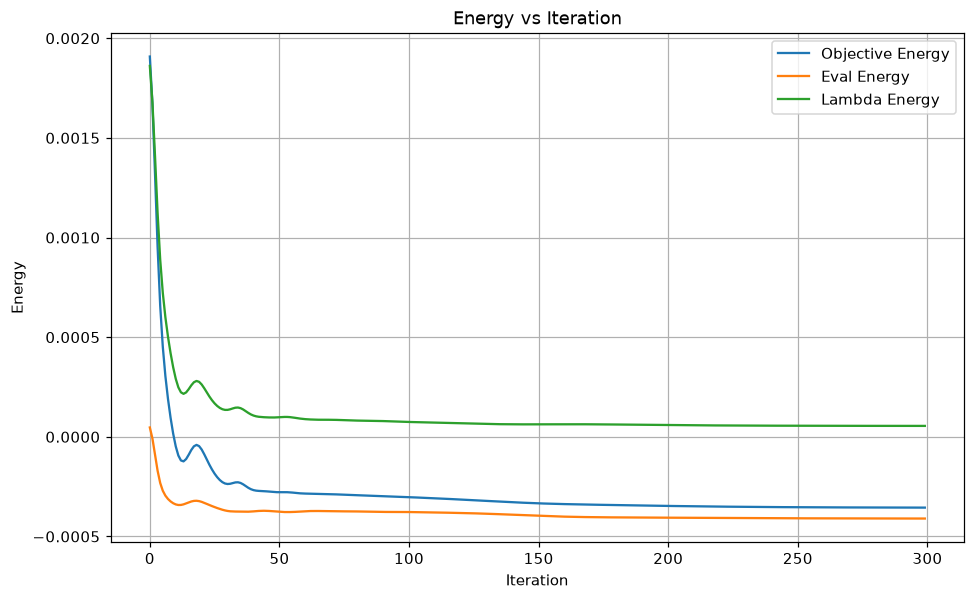

In [12]:
expectations = np.array(expectations)
plt.figure(figsize=(10, 6))
energy_obj = expectations[:, 0]
energy_eval = expectations[:, 1]
energy_lamb = expectations[:, 2]
plt.plot(energy_obj, label="Objective Energy")
plt.plot(energy_eval, label="Eval Energy")
plt.plot(energy_lamb, label="Lambda Energy")
plt.xlabel("Iteration")
plt.ylabel("Energy")
plt.title("Energy vs Iteration")
plt.legend()
plt.grid()
plt.show()

In [13]:
result = cudaq.get_state(kernel_qaoa_X, optimal_parameters, *ansatz_fixed_param)
idx_r_bests = np.argsort(np.abs(np.asarray(result)))[-5:][::-1]
idx_bests = [bin(idx_r)[2:].zfill(n_qubit)[::-1] for idx_r in idx_r_bests]

def all_state_to_return(qb, lam, QUBO): # QUBO of Max problem
    '''
    IMPORTANT: 
        QUBO: must be QUBO of MAX problem!!!
    '''
    ll = np.zeros((qb, 1<<qb), dtype=np.float32)
    a_0 = np.zeros(1<<qb, dtype=np.float32)
    a_1 = np.ones(1<<qb, dtype=np.float32)
    idxx = np.arange(1<<qb, dtype=np.int32)
    for i in range(qb):
        ll[i] = np.where(idxx%(1<<(qb-i))<(1<<(qb-i-1)), a_0,  a_1)
    l = ll.T.copy()
    ss = l @ QUBO
    ss = (ss.reshape(-1, 1, qb) @ l.reshape(-1, qb, 1))
    return ss.reshape(-1) - lam
state_optim = all_state_to_return(n_qubit, lamb, QU)
state_eval = all_state_to_return(n_qubit, 0.0, QU_eval)

result_r = cudaq.get_state(kernel_flipped, result, n_qubit)
prob = np.abs(np.asarray(result_r))**2
optimal_expectation = (prob * (state_eval)).sum()
print("Expected value:", optimal_expectation)

for i, idx_best in enumerate(idx_bests):
    print(f"\nOptimal binary string #{i+1}:", idx_best)
    vec_best = np.array([int(x) for x in idx_best])
    n_buy = E @ vec_best
    print("Number of each asset to buy:", n_buy)
    print("Budget used:", round(np.sum(n_buy * P), 2))
    print("Expected value: ", round(state_optim[int(idx_best, 2)], 7))
    print("Return minus risk:", round(state_eval[int(idx_best, 2)], 7))

Expected value: 0.00041005978961890075

Optimal binary string #1: 101001000100
Number of each asset to buy: [1. 1. 1. 1.]
Budget used: 849.06
Expected value:  0.0004366
Return minus risk: 0.000448

Optimal binary string #2: 101000000100
Number of each asset to buy: [1. 1. 0. 1.]
Budget used: 759.3
Expected value:  0.0003999
Return minus risk: 0.0004289

Optimal binary string #3: 101000100100
Number of each asset to buy: [1. 1. 2. 1.]
Budget used: 938.82
Expected value:  0.0004607
Return minus risk: 0.0004626

Optimal binary string #4: 101000000010
Number of each asset to buy: [1. 1. 0. 2.]
Budget used: 964.3
Expected value:  0.0004987
Return minus risk: 0.0004993

Optimal binary string #5: 001000100010
Number of each asset to buy: [0. 1. 2. 2.]
Budget used: 833.32
Expected value:  0.0004307
Return minus risk: 0.0004445


In [14]:
idx_best_evals = np.argsort(state_optim)[-5:][::-1]
for i, idx_best_eval in enumerate(idx_best_evals):
    idx_best_eval_bin = bin(idx_best_eval)[2:].zfill(n_qubit)
    print(f"\nOptimal binary string #{i+1} (evaluation):", idx_best_eval_bin)
    vec_best_eval = np.array([int(x) for x in idx_best_eval_bin])
    n_buy_eval = E @ vec_best_eval
    print("Number of each asset to buy (evaluation):", n_buy_eval)
    print("Budget used (evaluation):", round(np.sum(n_buy_eval * P), 2))
    print("Expected value (evaluation): ", round(state_optim[idx_best_eval], 7))
    print("Return minus risk (evaluation):", round(state_eval[idx_best_eval], 7))


Optimal binary string #1 (evaluation): 100100000010
Number of each asset to buy (evaluation): [1. 2. 0. 2.]
Budget used (evaluation): 1208.1
Expected value (evaluation):  0.0005367
Return minus risk (evaluation): 0.0005584

Optimal binary string #2 (evaluation): 001100000010
Number of each asset to buy (evaluation): [0. 3. 0. 2.]
Budget used (evaluation): 1141.39
Expected value (evaluation):  0.0005272
Return minus risk (evaluation): 0.0005372

Optimal binary string #3 (evaluation): 000100000110
Number of each asset to buy (evaluation): [0. 2. 0. 3.]
Budget used (evaluation): 1102.6
Expected value (evaluation):  0.0005269
Return minus risk (evaluation): 0.0005321

Optimal binary string #4 (evaluation): 000101000110
Number of each asset to buy (evaluation): [0. 2. 1. 3.]
Budget used (evaluation): 1192.36
Expected value (evaluation):  0.0005251
Return minus risk (evaluation): 0.0005436

Optimal binary string #5 (evaluation): 100101000010
Number of each asset to buy (evaluation): [1. 2. 

## Linear Ramp QAOA (LR-QAOA)

Normal QAOA above trains $2L$ parameters with a classical optimizer, which costs thousands of circuits. LR-QAOA ([Montanez-Barrera & Michielsen, arXiv:2405.09169](https://arxiv.org/abs/2405.09169)) removes the optimizer and takes the adiabatic picture literally: the cost Hamiltonian is switched on and the mixer is switched off along a fixed linear schedule.

$$
\gamma_\ell = \alpha \, \Delta_\gamma \frac{\ell}{L},
\qquad
\beta_\ell = -\Delta_\beta \left(1 - \frac{\ell - 1}{L}\right),
\qquad
\ell = 1, \dots, L
$$

For example, $L = 3$, $\alpha \Delta_\gamma = 3$ and $\Delta_\beta = 0.3$ give

| $\ell$ | 1 | 2 | 3 |
|---|---|---|---|
| $\gamma_\ell$ | 1 | 2 | 3 |
| $\beta_\ell$ | -0.3 | -0.2 | -0.1 |

There are only two numbers to choose, $\Delta_\gamma$ and $\Delta_\beta$, and each depth runs exactly one circuit. Two details decide whether the ramp works at all.

**The scale $\alpha$.** The kernel rotates by $2 c_j \gamma_\ell$, so $\gamma_\ell$ only has meaning relative to the coefficients $c_j$ (the $h_i$ and $J_{ij}$ of $H$), and these were multiplied by `hamiltonian_boost`. We set
$$
\alpha = \frac{1}{\max_j |c_j|},
$$
so the largest coefficient rotates by $2 \Delta_\gamma \ell / L$ and the schedule does not depend on the boost.

**The sign of $\beta$.** $\ket{+}^{\otimes n_\text{qb}}$ is the *highest* eigenstate of $H_X = \sum_i X_i$, and adiabatic evolution stays on the eigenstate it starts from. With $\beta_\ell > 0$ the ramp would therefore end on the **maximum** of $H(\lambda)$, the worst portfolio. Since $e^{-i\beta H_X} = e^{-i|\beta|(-H_X)}$ for $\beta < 0$, a negative $\beta_\ell$ means the mixer is really $-H_X$. Now $\ket{+}^{\otimes n_\text{qb}}$ is its ground state, and the ramp follows the ground state down to the minimum of $H(\lambda)$.

In [15]:
import time

lr_layer_list = [3, 5, 10, 20, 50]
qaoa_layer_list = [3, 5, 10]
delta_gamma = 2.0
delta_beta = 0.3

# Every run of both methods is stored as results[(method, L)], so re-running a cell overwrites its old row
results = {}

obj_max, obj_min = state_optim.max(), state_optim.min()
idx_optimal = np.argmax(state_optim)

def qaoa_args(L):
    return (int(n_qubit), L, idx_1_use, coeff_1_use, idx_2_a_use, idx_2_b_use, coeff_2_use)

def collect_result(method, L, thetas, n_circuits, seconds):
    # Exact probabilities, used only to report the result (same steps as the evaluation above)
    state = cudaq.get_state(kernel_qaoa_X, thetas, *qaoa_args(L))
    prob = np.abs(np.asarray(cudaq.get_state(kernel_flipped, state, n_qubit)))**2
    exp_objective = (prob * state_optim).sum()

    # Approximation ratio of exp_objective: 0 for the worst bitstring, 1 for the optimal one
    approx_ratio = float((exp_objective - obj_min) / (obj_max - obj_min)) if obj_max > obj_min else 1.0
    # Probability of measuring the optimal bitstring
    p_optimal = float(prob[idx_optimal])

    idx_top = int(np.argmax(prob))
    top_string = format(idx_top, f"0{n_qubit}b")
    n_buy_top = E @ np.array([int(x) for x in top_string])
    results[(method, L)] = {
        "method": method,
        "L": L,
        "exp_objective": exp_objective,
        "exp_return": (prob * state_eval).sum(),
        "approx_ratio": approx_ratio,
        "p_optimal": p_optimal,
        "top_string": top_string,
        "top_budget": round(np.sum(n_buy_top * P), 2),
        "n_circuits": n_circuits,
        "seconds": seconds,
    }
    print(f"{method:8s} L={L:3d}  approx_ratio={approx_ratio:.4f}  p_optimal={p_optimal:.4f}  n_circuits={n_circuits:6d}  time={seconds:.2f}s")

In [16]:
def linear_ramp_params(L, delta_gamma, delta_beta, alpha):
    '''
    Returns the angles in the order kernel_qaoa_X reads them: [gamma_1, ..., gamma_L, beta_1, ..., beta_L]
    '''
    if not isinstance(L, (int, np.integer)) or L < 1:
        raise ValueError('L must be a positive integer.')
    ell = np.arange(1, L + 1)
    gammas = alpha * delta_gamma * ell / L
    betas = -delta_beta * (1 - (ell - 1) / L)
    return np.concatenate([gammas, betas])

# alpha from the largest coefficient of the cost Hamiltonian (coeff_1_use holds h_i, coeff_2_use holds J_ij)
max_coefficient = np.max(np.abs(np.concatenate([coeff_1_use, coeff_2_use])), initial=0.0)
alpha = 1.0 / max_coefficient if max_coefficient > 0 else 1.0

print(linear_ramp_params(3, 3.0, 0.3, 1.0))  # Should print [ 1.   2.   3.  -0.3 -0.2 -0.1]

[ 1.   2.   3.  -0.3 -0.2 -0.1]


In [17]:
for L in lr_layer_list:
    t0 = time.time()
    thetas = linear_ramp_params(L, delta_gamma, delta_beta, alpha)
    energy = cudaq.observe(kernel_qaoa_X, H, thetas, *qaoa_args(L)).expectation()  # The only circuit LR-QAOA needs
    seconds = time.time() - t0
    collect_result("LR-QAOA", L, thetas, 1, seconds)

LR-QAOA  L=  3  approx_ratio=0.9582  p_optimal=0.0016  n_circuits=     1  time=0.01s
LR-QAOA  L=  5  approx_ratio=0.9709  p_optimal=0.0023  n_circuits=     1  time=0.01s
LR-QAOA  L= 10  approx_ratio=0.9834  p_optimal=0.0051  n_circuits=     1  time=0.01s
LR-QAOA  L= 20  approx_ratio=0.9899  p_optimal=0.0090  n_circuits=     1  time=0.02s
LR-QAOA  L= 50  approx_ratio=0.9945  p_optimal=0.0246  n_circuits=     1  time=0.04s


### Normal QAOA at 3, 5 and 10 layers

We train normal QAOA with the same optimizer settings as the training loop above. Each comparison run uses a fresh generator seeded with `seed`; the earlier demonstration used the global generator after asset selection, so its initial point differs.

We stop at $L = 10$ because the forward finite difference needs one extra circuit per parameter at every iteration, so training gets expensive quickly.

In [18]:
def train_qaoa(L):
    '''
    Same optimizer and settings as the training loop above, at depth L.
    Returns the trained parameters and the number of iterations.
    '''
    points = np.random.default_rng(seed).uniform(-0.01, 0.01, 2 * L)
    points_cu = torch.tensor(points, dtype=torch.float64, device=device)
    optimizer = AdamW([points_cu], lr=0.01, betas=(0.95, 0.98), weight_decay=0.01)
    scheduler = CosineAnnealingLR(optimizer, T_max=max_iter, eta_min=0.0003)

    num_iter, cou_con, last_f = 0, 0, None
    pbar = tqdm(range(max_iter), disable=not is_pbar, desc=f"QAOA L={L}")
    for it in pbar:
        params = points_cu.detach().cpu().numpy().copy()
        expectation = float(cudaq.observe(kernel_qaoa_X, H, params, *qaoa_args(L)).expectation())
        num_iter += 1

        grad = torch.zeros_like(points_cu)
        for j in range(2 * L):
            shift = np.zeros(2 * L)
            shift[j] = SHIFT
            # Forward finite difference, as in the training loop above
            forward = float(cudaq.observe(kernel_qaoa_X, H, params + shift, *qaoa_args(L)).expectation())
            grad[j] = (forward - expectation) / SHIFT
        points_cu.grad = grad
        optimizer.step()
        scheduler.step()

        cou_con = cou_con + 1 if last_f is not None and abs(expectation - last_f) < F_TOL else 0
        if cou_con >= 3:
            break
        last_f = expectation
        pbar.set_postfix(Exp_obj=f"{expectation / hamiltonian_boost:.6f}")
    return points_cu.detach().cpu().numpy().copy(), num_iter

for L in qaoa_layer_list:
    t0 = time.time()
    thetas, num_iter = train_qaoa(L)
    seconds = time.time() - t0
    # Circuits the optimizer ran: at each iteration, one for the energy and one per parameter for the gradient
    n_circuits = num_iter * (1 + 2 * L)
    collect_result("QAOA", L, thetas, n_circuits, seconds)

QAOA     L=  3  approx_ratio=0.9815  p_optimal=0.0021  n_circuits=  2100  time=12.75s
QAOA     L=  5  approx_ratio=0.9856  p_optimal=0.0035  n_circuits=  3300  time=25.54s
QAOA     L= 10  approx_ratio=0.9900  p_optimal=0.0070  n_circuits=  5901  time=74.63s


### Compare normal QAOA and LR-QAOA

`results_df` holds every run. The table below puts both methods side by side for each depth.

In [19]:
results_df = pd.DataFrame(list(results.values())).sort_values(["L", "method"]).reset_index(drop=True)
display(results_df)

comparison = results_df.pivot(index="L", columns="method", values=["approx_ratio", "p_optimal", "n_circuits", "seconds"])
display(comparison)

,method,L,exp_objective,exp_return,approx_ratio,p_optimal,top_string,top_budget,n_circuits,seconds
0,LR-QAOA,3,-0.000003,0.000313,0.958188,0.001580,000010000000,975.19,1,0.006719
1,QAOA,3,0.000299,0.000375,0.981538,0.002116,000010000000,975.19,2100,12.745463
2,LR-QAOA,5,0.000162,0.000346,0.970922,0.002324,000010000000,975.19,1,0.007087
3,QAOA,5,0.000351,0.000409,0.985610,0.003474,101001000100,849.06,3300,25.541819
4,LR-QAOA,10,0.000323,0.000455,0.983409,0.005092,101001000110,1259.06,1,0.012157
5,QAOA,10,0.000408,0.000452,0.990019,0.006974,101001100100,1028.58,5901,74.630957
6,LR-QAOA,20,0.000407,0.000471,0.989942,0.008998,000100000110,1102.60,1,0.020854
7,LR-QAOA,50,0.000466,0.000497,0.994522,0.024595,000100000110,1102.60,1,0.043294


approx_ratio           p_optimal  ... n_circuits   seconds           
method      LR-QAOA      QAOA   LR-QAOA  ...       QAOA   LR-QAOA       QAOA
L                                        ...                                
3          0.958188  0.981538  0.001580  ...     2100.0  0.006719  12.745463
5          0.970922  0.985610  0.002324  ...     3300.0  0.007087  25.541819
10         0.983409  0.990019  0.005092  ...     5901.0  0.012157  74.630957
20         0.989942       NaN  0.008998  ...        NaN  0.020854        NaN
50         0.994522       NaN  0.024595  ...        NaN  0.043294        NaN

[5 rows x 8 columns]

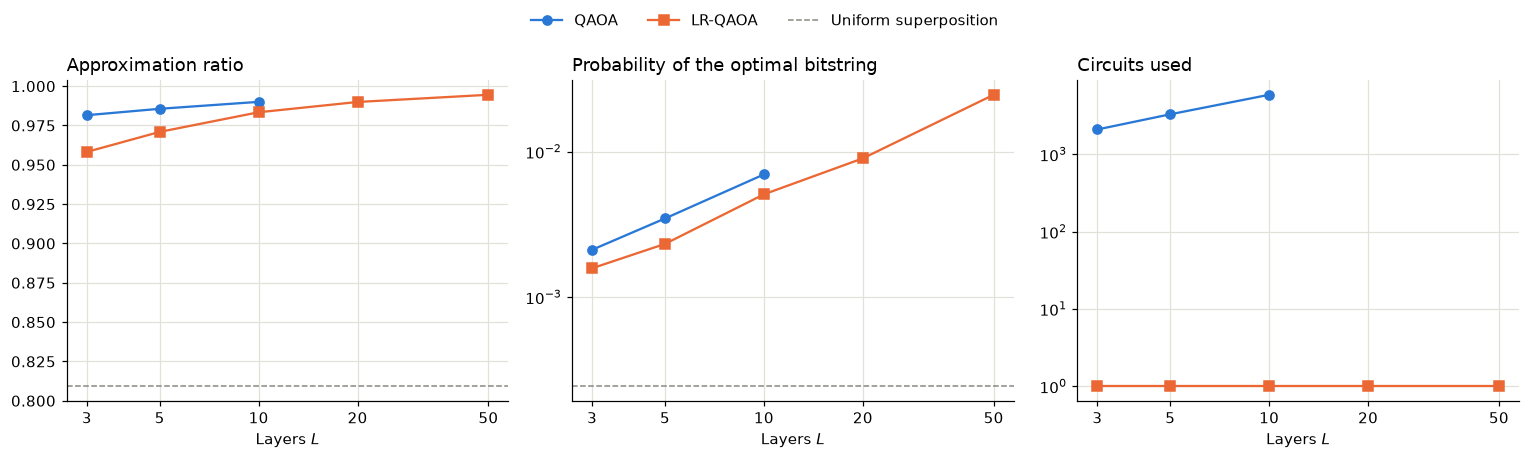

In [20]:
method_style = {"QAOA": dict(color="#2a78d6", marker="o"), "LR-QAOA": dict(color="#eb6834", marker="s")}
panels = [
    ("approx_ratio", "Approximation ratio", "linear", (state_optim.mean() - obj_min) / (obj_max - obj_min)),
    ("p_optimal", "Probability of the optimal bitstring", "log", 1 / 2**n_qubit),
    ("n_circuits", "Circuits used", "log", None),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (column, title, yscale, uniform) in zip(axes, panels):
    for method, style in method_style.items():
        rows = results_df[results_df["method"] == method]
        ax.plot(rows["L"], rows[column], label=method, linewidth=1.5, markersize=6, **style)
    if uniform is not None:
        ax.axhline(uniform, color="#898781", linewidth=1, linestyle="--", label="Uniform superposition")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Layers $L$")
    ax.set_xscale("log")
    ax.set_yscale(yscale)
    ax.set_xticks(lr_layer_list)
    ax.set_xticklabels(lr_layer_list)
    ax.minorticks_off()
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

In [21]:
# Questions 3 and 4: evaluate alternate schedules without changing the defaults
# or overwriting the QAOA/LR-QAOA comparison table.
schedule_rows = []
for label, dg, db, sign in [('default', 2.0, 0.3, -1),
                            ('positive beta', 2.0, 0.3, 1),
                            ('small mixer', 3.0, 0.2, -1),
                            ('large mixer', 3.0, 1.0, -1)]:
    for L in lr_layer_list:
        angles = linear_ramp_params(L, dg, db, alpha)
        if sign > 0:
            angles[L:] *= -1
        state = cudaq.get_state(kernel_qaoa_X, angles, *qaoa_args(L))
        probs = np.abs(np.asarray(cudaq.get_state(kernel_flipped, state, n_qubit)))**2
        value = float(probs @ state_optim)
        schedule_rows.append(dict(schedule=label, L=L, exp_objective=value,
                                  approx_ratio=(value - obj_min) / (obj_max - obj_min),
                                  p_optimal=float(probs[idx_optimal])))
schedule_df = pd.DataFrame(schedule_rows)
display(schedule_df)
display(schedule_df.pivot(index='L', columns='schedule', values=['approx_ratio', 'p_optimal']))

# Gate counts before connectivity routing or compiler cancellations.
n_linear, n_pairs = len(idx_1_use), len(idx_2_a_use)
gate_df = results_df[['method', 'L', 'n_circuits']].copy()
gate_df['one_qubit_gates'] = n_qubit + gate_df.L * (n_linear + n_pairs + n_qubit)
gate_df['CNOT_gates'] = 2 * n_pairs * gate_df.L
gate_df['total_gates'] = gate_df.one_qubit_gates + gate_df.CNOT_gates
display(gate_df)
print('All metrics optimize the soft-penalty objective; feasibility must be checked separately.')
print('Circuit counts are ideal state preparations for training/schedule evaluation;')
print('they exclude reporting states, measurement shots, and hardware calibration.')

All metrics optimize the soft-penalty objective; feasibility must be checked separately.
Circuit counts are ideal state preparations for training/schedule evaluation;
they exclude reporting states, measurement shots, and hardware calibration.


,schedule,L,exp_objective,approx_ratio,p_optimal
0,default,3,-0.000003,0.958188,1.580063e-03
1,default,5,0.000162,0.970922,2.323894e-03
2,default,10,0.000323,0.983409,5.091714e-03
3,default,20,0.000407,0.989942,8.997904e-03
4,default,50,0.000466,0.994522,2.459501e-02
5,positive beta,3,-0.004939,0.575472,9.438331e-06
6,positive beta,5,-0.005893,0.501502,2.250065e-06
7,positive beta,10,-0.007322,0.390657,6.112614e-08
8,positive beta,20,-0.008528,0.297212,1.286918e-09
9,positive beta,50,-0.009346,0.233765,8.274508e-11


approx_ratio              ...     p_optimal            
schedule      default large mixer  ... positive beta small mixer
L                                  ...                          
3            0.958188    0.854848  ...  9.438331e-06    0.001381
5            0.970922    0.899071  ...  2.250065e-06    0.002008
10           0.983409    0.927507  ...  6.112614e-08    0.005061
20           0.989942    0.926341  ...  1.286918e-09    0.016016
50           0.994522    0.912655  ...  8.274508e-11    0.047566

[5 rows x 8 columns]

,method,L,n_circuits,one_qubit_gates,CNOT_gates,total_gates
0,LR-QAOA,3,1,282,396,678
1,QAOA,3,2100,282,396,678
2,LR-QAOA,5,1,462,660,1122
3,QAOA,5,3300,462,660,1122
4,LR-QAOA,10,1,912,1320,2232
5,QAOA,10,5901,912,1320,2232
6,LR-QAOA,20,1,1812,2640,4452
7,LR-QAOA,50,1,4512,6600,11112


In [22]:
# Exhaustive consistency checks for this small (12-qubit) instance.
basis_bits = ((np.arange(1 << n_qubit)[:, None] >>
               np.arange(n_qubit - 1, -1, -1)) & 1).astype(float)
shares_all = basis_bits @ E.T
weights_all = shares_all * P / B
direct_eval = weights_all @ ret - q * np.einsum('bi,ij,bj->b', weights_all, cov, weights_all)
direct_penalty = lamb * (weights_all.sum(axis=1) - 1)**2
np.testing.assert_allclose(state_eval, direct_eval, atol=1e-14)
np.testing.assert_allclose(state_optim, direct_eval - direct_penalty, atol=1e-14)

# Reconstruct every Ising diagonal entry, including the identity offset.
raw_terms, raw_coefficients = H.get_raw_data()
ising_diagonal = np.zeros(1 << n_qubit)
for term, coefficient in zip(raw_terms, raw_coefficients):
    width = len(term) // 2
    assert not any(term[:width]), 'This Hamiltonian should contain only I and Z.'
    support = np.flatnonzero(term[width:])
    ising_diagonal += coefficient.real * np.prod(1 - 2 * basis_bits[:, support], axis=1)
np.testing.assert_allclose(ising_diagonal, -hamiltonian_boost * state_optim, atol=1e-11)
np.testing.assert_allclose(linear_ramp_params(3, 3.0, 0.3, 1.0), [1, 2, 3, -0.3, -0.2, -0.1])
np.testing.assert_allclose(prob.sum(), 1.0, atol=1e-12)
assert np.all(linear_ramp_params(5, delta_gamma, delta_beta, alpha)[5:] < 0)
print(f'Passed: objective, QUBO, and Ising agree on all {1 << n_qubit:,} bitstrings;')
print('state probabilities are normalized and the default mixer sign is restored.')

Passed: objective, QUBO, and Ising agree on all 4,096 bitstrings;
state probabilities are normalized and the default mixer sign is restored.


### Questions

These answers use the executed, noiseless NumPy state-vector runs with seed 55
and the original default parameters. Circuit counts count ideal state preparations
for optimization or schedule evaluation; they exclude reporting, repeated shots,
and the separate schedule experiments. The optimum is the **soft-penalty optimum**:
its shares are `[1, 2, 0, 2]` (ACN, JPM, MRK, DHR), spending $1,208.10.
It therefore exceeds the $1,000 budget. None of these comparisons establishes
that the returned portfolio satisfies a hard budget constraint. A ratio near one
can also be misleading here because heavily overspending bitstrings make the
worst objective very negative; inspect optimal-bitstring probability alongside it.

1. At $L = 3, 5, 10$, which method has the better approximation ratio and the better probability of the optimal bitstring? How many circuits did each one pay for it?

**Ans**: Trained QAOA wins on both metrics at every common depth in this run:

| $L$ | QAOA ratio | LR-QAOA ratio | QAOA $p_\mathrm{optimal}$ | LR-QAOA $p_\mathrm{optimal}$ | QAOA circuits | LR-QAOA circuits |
|---|---:|---:|---:|---:|---:|---:|
| 3 | 0.981538 | 0.958188 | 0.002116 | 0.001580 | 2,100 | 1 |
| 5 | 0.985610 | 0.970922 | 0.003474 | 0.002324 | 3,300 | 1 |
| 10 | 0.990019 | 0.983409 | 0.006974 | 0.005092 | 5,901 | 1 |

Forward finite differences require $1+2L$ evaluations per iteration. The runs
used 300, 300, and 281 iterations, respectively; the last stopped early. These
are results for this instance and initialization, not a universal method ranking.
One ideal expectation evaluation still requires many measurement shots on hardware.

2. How deep does LR-QAOA have to go to match normal QAOA at $L = 10$? Compare the two in circuits run and in gates per circuit.

**Ans**: Among the tested depths, **$L=50$ is the first that beats both metrics**
of trained QAOA at $L=10$: ratio 0.994522 versus 0.990019, and optimal-string
probability 0.024595 versus 0.006974. At $L=20$, LR-QAOA almost matches the
ratio (0.989942) and already exceeds its optimal-string probability (0.008998).
The experiment does not locate the exact first matching depth between 20 and 50.

LR-QAOA uses 1 evaluation versus 5,901 for QAOA. However, its individual circuit
is about five times as long. There are 12 qubits, 12 linear terms, and 66 pair
terms. Each layer uses 12 RZ gates, 66 RZ gates inside CX-RZ-CX blocks, 132
CNOTs, and 12 RX gates: 222 gates. Including the initial 12 Hadamards gives
$G(L)=12+222L$. Thus QAOA at $L=10$ has **2,232 gates (1,320 CNOTs)** per
circuit, while LR-QAOA at $L=50$ has **11,112 gates (6,600 CNOTs)**. These
counts precede routing and compiler cancellations; they are gate counts, not
scheduled hardware circuit depth.

3. Make $\beta_\ell$ positive in `linear_ramp_params` and re-run the LR-QAOA cell and the comparison cells. What happens as $L$ grows, and why? Remember to change it back.

**Ans**: The `positive beta` experiment flips only the mixer sign and preserves
the original comparison results. Its ratio falls through 0.575472, 0.501502,
0.390657, 0.297212, and 0.233765 for $L=3,5,10,20,50$. The probability of
the optimal string drops from $9.44\times10^{-6}$ to $8.27\times10^{-11}$.
The expected minimization energy increases, so portfolio quality deteriorates.

With positive beta, the mixer is $+H_X$. The initial $|+\rangle^{\otimes n}$
is its highest-energy eigenstate. In the ideal adiabatic picture it follows the
upper branch toward the maximum of the minimization Hamiltonian $H$, which
is the minimum of the portfolio objective. Negative beta instead implements
$-H_X$, whose ground state is the initial state. Finite digital ramps need not
reach either extremum exactly, but the observed trend agrees with this sign
argument. The default function still returns **negative beta** after the experiment.

4. Try $(\Delta_\gamma, \Delta_\beta) = (3.0, 0.2)$ and $(3.0, 1.0)$. Which of them keeps improving with $L$? Why do large angles per layer break the adiabatic picture? (Hint: look at the Trotter error above.)

**Ans**: **$(3.0,0.2)$ keeps improving in approximation ratio** across all tested
depths: 0.911635, 0.937279, 0.963761, 0.983465, 0.994415. Its optimal-string
probability also increases, reaching 0.047566 at $L=50$.

For $(3.0,1.0)$, the ratio rises from 0.854848 to 0.927507 at $L=10$, then
falls to 0.926341 at $L=20$ and 0.912655 at $L=50$. Its optimal-string
probability still increases to 0.011746, so the failure of monotonic improvement
is in the **mean objective**, not every metric of the distribution.

The cost and mixer do not commute. In splitting
$e^{-i\beta H_X}e^{-i\gamma H_C}$, the leading commutator correction has
size proportional to $|\beta\gamma|\|[H_X,H_C]\|$; large steps and higher-order
terms can create transitions that invalidate the continuous adiabatic picture.
Increasing $L$ here slows the change of the schedule but does **not** shrink its
maximum per-layer angles, so it need not remove this digital splitting error.
The cost terms themselves are all diagonal Z strings and commute: their
CX-RZ-CX decomposition has no Trotter error. Normalizing the largest individual
coefficient also does not bound the norm of the entire Hamiltonian.

5. A real device has noise that grows with circuit depth and a cost per circuit. Compare normal QAOA at $L = 10$ with LR-QAOA at $L = 50$: which would you run on it, and why?

**Ans**: On a device whose noise strongly limits depth, I would start with
**QAOA at $L=10$**, preferably training on a simulator and then measuring the
fixed angles on hardware. Its 1,320 CNOTs per circuit give it a better chance
of surviving noise than LR-QAOA's 6,600. The extra 5,280 CNOTs can erase
LR-QAOA's noiseless advantage (optimal-string probability 0.024595 versus
0.006974).

If optimization must also run on hardware and per-circuit cost dominates,
**LR-QAOA at $L=50$ is attractive**: it avoids 5,901 training evaluations and
has better ideal metrics, provided the device can tolerate its longer circuit.
The question gives no noise rates or price model, so there is no unconditional
winner. I would compare measured success per total shot cost. Both methods
need repeated shots to obtain a portfolio, and finite-shot gradients add cost
and uncertainty to QAOA training. Any chosen portfolio must also pass a budget
check because the optimum used in this lab overspends.